# Scene gaze and inquiry into a boundary

This companion executes the finite intersection model from the manuscript. Scene queries learn appearance; paired action–response questions can inform a predictive encoding. Their joint use is evaluated in an explicitly anchored reference condition. This is structural inquiry, not recorded human gaze, measured metacognitive sensitivity, or a state of realization.

Read the [design contract](../docs/boundary-gaze-design.md) and [primary-source dossier](../docs/boundary-gaze-research.md). Other companions cover [belief updating](belief_updating.ipynb), [visual gaze](gaze_emptiness.ipynb), and [appreciation and practice](gratitude_absence.ipynb). Run the canonical pipeline before this notebook to produce its source-bound records and figures.

In [1]:
import sys
from thanks_for_nothing.notebooks import notebook_context
context = notebook_context()
from pathlib import Path
import numpy as np
from IPython.display import Image, Markdown, display
from thanks_for_nothing import __version__
from thanks_for_nothing.artifact_checks import read_record
from thanks_for_nothing.boundary_contracts import BoundaryGazeAudit
from thanks_for_nothing.boundary_design import load_boundary_task, contingency_channel
from thanks_for_nothing.boundary_math import joint_prediction
from thanks_for_nothing.boundary_sampling import make_exposure, run_boundary_episode
from thanks_for_nothing.boundary_statistics import admit_boundary_records, boundary_estimates
from thanks_for_nothing.boundary_study import boundary_mathematical_controls
from thanks_for_nothing.boundary_upstream import BoundaryUpstreamAudit, build_boundary_upstream
from thanks_for_nothing.boundary_findings import boundary_interval_table

ROOT = context.root
OUTPUT = context.output
vault_root = next(parent for parent in ROOT.parents if parent.name == "GitVault")
assert vault_root.is_mount()
assert Path(sys.prefix).resolve().is_relative_to(vault_root)
assert Path(sys.base_prefix).resolve().is_relative_to(vault_root)
print("Version:", __version__, "interpreter:", sys.executable)

Version: 0.11.0 interpreter: /Volumes/GitVault/Local/environments/tfn-release-20261022-311/bin/python


## Actual GNN and Realizing Emptiness admission

The joint declaration composes the existing admitted gaze channels and actual native support. Every fixed stratum receives independent replicate identities. The declared policies share complete potential outcomes; decisions and policy conditions do not increase the independent N.

In [2]:
task = load_boundary_task(context.specifications)
assert all(boundary_mathematical_controls(task).values())
print("Declaration:", task.model.source_hash)
print("Queries/outcomes/joint states:", task.diagnostic.shape)
boundary_count = len(task.design.scene_maps)
print("H prior under native restriction:", task.restricted_prior.reshape(-1, boundary_count).sum(axis=0))
print("Independent paired units:", len(task.design.regimes) * task.restricted_prior.size * task.design.replicates)
print("Decisions per policy episode:", task.design.steps)

Declaration: 4d0b48141d3b6738b215cda42546a6b2c2f467e2bb7327132819a9727775a453
Queries/outcomes/joint states: (16, 9, 9)
H prior under native restriction: [0.5 0.5 0. ]
Independent paired units: 9216
Decisions per policy episode: 24


In [3]:
audit = read_record(OUTPUT / "data/boundary_gaze.json", BoundaryGazeAudit)
admit_boundary_records(task, audit.episodes)
region, offsets, convergence = boundary_estimates(task, audit.episodes)
assert region == audit.region and offsets == audit.exact_offsets and convergence == audit.convergence
assert audit.all_controls_pass and all(audit.controls.values())
print("Paired episodes:", len(audit.episodes))
print("Joint family:", len(region.intervals), "proved constants:", len(offsets), "status:", region.status)
print("Critical value:", region.critical_value)
print("Conditional quantile MC bracket:", region.critical_mc_low, region.critical_mc_high)

Paired episodes: 55296
Joint family: 84 proved constants: 30 status: complete
Critical value: 3.319630699959646
Conditional quantile MC bracket: 3.2748554552868097 3.361183247195598


## Equal marginals do not imply equal joint laws

The independent binary fixture below is an authored mathematical check. Each bit alone has the same probability under both candidates, while paired bits from the same event convey information. Independent bits sampled from different events would be a different experiment. The actual ternary probes have uniform action and response marginals too.

In [4]:
fixture = np.array([[.45, .05], [.05, .45], [.05, .45], [.45, .05]])
prediction, information = joint_prediction(fixture[None, :, :], np.array([.5, .5]))
assert np.allclose(fixture.reshape(2, 2, 2).sum(axis=0), .5)
assert np.allclose(fixture.reshape(2, 2, 2).sum(axis=1), .5)
assert abs(information[0] - .3680642071684971) < 1e-12
for reliability in task.design.probe_reliabilities:
    channel = contingency_channel(reliability).reshape(3, 3, 3)
    assert np.allclose(channel.sum(axis=0), 1/3)
    assert np.allclose(channel.sum(axis=1), 1/3)
print("Joint information in the independent fixture:", information[0], "nats")

Joint information in the independent fixture: 0.36806420716849697 nats


## Imported boundary analyses have different scopes

QRF label equality is a constructed equality of complete distributions. The Gaussian fixture asks whether thresholding marginal correlations recovers a known blanket. A failure of that threshold does not imply failure of full covariance inversion. The six Gaussian variables are not a biological mapping of the six QRF bits.

In [5]:
upstream = read_record(OUTPUT / "data/boundary_upstream.json", BoundaryUpstreamAudit)
assert upstream == build_boundary_upstream()
assert upstream.all_controls_pass
precision = np.asarray(upstream.precision_matrix)
assert np.max(abs(np.linalg.inv(np.linalg.inv(precision)) - precision)) < 1e-12
print("Best exhaustive marginal-threshold F1:", upstream.exhaustive_marginal_best_f1)
print("Known-covariance inversion error:", upstream.covariance_inverse_error)
print("Admitted perturbation denominator:", upstream.positive_definite_samples, "/", upstream.perturbation_samples)

Best exhaustive marginal-threshold F1: 0.8
Known-covariance inversion error: 4.440892098500626e-16
Admitted perturbation denominator: 200 / 200


## Reproduce a paired example and its nonautonomous sham

At the first scene and excluded encoding H2, replicate zero is fixed independently of its effect. The sham receives the integrated schedule and erases action identity in its updater. It ignores information in the demonstrator's adaptive schedule, so it is not a globally information-free or autonomous attention model.

In [6]:
exposure = make_exposure(task, "diagnostic", 0, 2, 0)
integrated = run_boundary_episode(task, exposure, "integrated")
sham = run_boundary_episode(task, exposure, "sham", yoked_queries=integrated.queries)
for condition, replayed in (("integrated", integrated), ("sham", sham)):
    retained = next(r for r in audit.episodes if (r.regime, r.scene, r.boundary, r.replicate, r.condition) == ("diagnostic", 0, 2, 0, condition))
    assert retained == replayed
    print(condition, "H posterior:", replayed.final_boundary, "Z posterior:", replayed.final_scene)
    print("Anchored regret:", replayed.anchored_regret, "boundary Brier:", replayed.boundary_brier)
assert integrated.queries == sham.queries and integrated.outcomes == sham.outcomes
assert integrated.mean_cost == sham.mean_cost

integrated H posterior: (0.024999999999999918, 0.02499999999999992, 0.9500000000000001) Z posterior: (0.9499999960090375, 0.025000001995481212, 0.025000001995481212)
Anchored regret: 0.0008763681147988665 boundary Brier: 0.0037499999999999855
sham H posterior: (0.33333333333333337, 0.3333333333333333, 0.3333333333333333) Z posterior: (0.33333333333333337, 0.3333333333333333, 0.3333333333333333)
Anchored regret: 0.11533854091161805 boundary Brier: 0.6666666666666667


## More independent units, not more pseudo-replicates

Prefixes were declared before the run. Their estimates share earlier units and are correlated; the standard errors quantify Monte Carlo sampling of independent paired replicates. They are not human population uncertainty or a power calculation. Label-equivalent encoding odds cannot change with larger N.

In [7]:
assert make_exposure(task, "diagnostic", 0, 2, 0).sha256 != make_exposure(task, "diagnostic", 0, 2, 1).sha256
for row in audit.convergence:
    if (row.regime, row.boundary, row.condition, row.reference, row.endpoint) == ("diagnostic", 2, "integrated", "visual", "anchored_regret"):
        print(row.replicates_per_stratum, row.mean, row.standard_error)
for row in audit.episodes:
    if row.regime == "label_only" and row.condition != "restricted":
        assert np.allclose(row.final_boundary, [1/3]*3, atol=1e-12)
print("Exact label-only posterior identities retained.")

16 -0.08725903849286959 0.010640541715646873
32 -0.0884894446398291 0.006629849276594417
64 -0.0819744074217375 0.0061309500484729934
128 -0.07817949423729964 0.00487509360913048
256 -0.08116209317680816 0.0031135354112402608
512 -0.07931372783210493 0.0021900615152784775


Exact label-only posterior identities retained.


In [8]:
display(Markdown(boundary_interval_table(audit)))

| Regime / H | Contrast | Endpoint | Mean | Joint interval | Status |
| --- | --- | --- | ---: | --- | --- |
| diagnostic / H0 | Integrated - Visual only | Anchor loss | -0.101220 | [-0.107449, -0.094991] | estimated |
| diagnostic / H0 | Integrated - Visual only | Boundary Brier | -0.612571 | [-0.638418, -0.586724] | estimated |
| diagnostic / H0 | Boundary only - Visual only | Anchor loss | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H0 | Boundary only - Visual only | Boundary Brier | -0.666667 | [-0.666667, -0.666667] | estimated |
| diagnostic / H0 | Uniform - Visual only | Anchor loss | -0.096426 | [-0.101357, -0.091495] | estimated |
| diagnostic / H0 | Uniform - Visual only | Boundary Brier | -0.591520 | [-0.614552, -0.568488] | estimated |
| diagnostic / H0 | Restricted - Visual only | Anchor loss | -0.105880 | [-0.110288, -0.101473] | estimated |
| diagnostic / H0 | Restricted - Visual only | Boundary Brier | -0.616534 | [-0.641923, -0.591145] | estimated |
| diagnostic / H0 | Yoked sham - Visual only | Anchor loss | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H0 | Yoked sham - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H0 | Integrated - Uniform | Anchor loss | -0.004794 | [-0.012426, 0.002838] | estimated |
| diagnostic / H0 | Integrated - Uniform | Boundary Brier | -0.021051 | [-0.053491, 0.011389] | estimated |
| diagnostic / H0 | Integrated - Boundary only | Anchor loss | -0.101220 | [-0.107449, -0.094991] | estimated |
| diagnostic / H0 | Integrated - Boundary only | Boundary Brier | 0.054096 | [0.028249, 0.079943] | estimated |
| diagnostic / H1 | Integrated - Visual only | Anchor loss | -0.054426 | [-0.064589, -0.044263] | estimated |
| diagnostic / H1 | Integrated - Visual only | Boundary Brier | -0.611300 | [-0.637446, -0.585153] | estimated |
| diagnostic / H1 | Boundary only - Visual only | Anchor loss | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H1 | Boundary only - Visual only | Boundary Brier | -0.666667 | [-0.666667, -0.666667] | estimated |
| diagnostic / H1 | Uniform - Visual only | Anchor loss | -0.046550 | [-0.055812, -0.037287] | estimated |
| diagnostic / H1 | Uniform - Visual only | Boundary Brier | -0.584887 | [-0.608699, -0.561076] | estimated |
| diagnostic / H1 | Restricted - Visual only | Anchor loss | -0.057989 | [-0.068054, -0.047924] | estimated |
| diagnostic / H1 | Restricted - Visual only | Boundary Brier | -0.625979 | [-0.648755, -0.603203] | estimated |
| diagnostic / H1 | Yoked sham - Visual only | Anchor loss | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H1 | Yoked sham - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H1 | Integrated - Uniform | Anchor loss | -0.007876 | [-0.021187, 0.005435] | estimated |
| diagnostic / H1 | Integrated - Uniform | Boundary Brier | -0.026412 | [-0.060705, 0.007881] | estimated |
| diagnostic / H1 | Integrated - Boundary only | Anchor loss | -0.054426 | [-0.064589, -0.044263] | estimated |
| diagnostic / H1 | Integrated - Boundary only | Boundary Brier | 0.055367 | [0.029220, 0.081514] | estimated |
| diagnostic / H2 | Integrated - Visual only | Anchor loss | -0.079314 | [-0.086584, -0.072044] | estimated |
| diagnostic / H2 | Integrated - Visual only | Boundary Brier | -0.618498 | [-0.642679, -0.594317] | estimated |
| diagnostic / H2 | Boundary only - Visual only | Anchor loss | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H2 | Boundary only - Visual only | Boundary Brier | -0.666667 | [-0.666667, -0.666667] | estimated |
| diagnostic / H2 | Uniform - Visual only | Anchor loss | -0.065590 | [-0.072833, -0.058347] | estimated |
| diagnostic / H2 | Uniform - Visual only | Boundary Brier | -0.600923 | [-0.621706, -0.580141] | estimated |
| diagnostic / H2 | Restricted - Visual only | Anchor loss | 0.115680 | [0.101109, 0.130252] | estimated |
| diagnostic / H2 | Restricted - Visual only | Boundary Brier | 1.127626 | [1.110108, 1.145144] | estimated |
| diagnostic / H2 | Yoked sham - Visual only | Anchor loss | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H2 | Yoked sham - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| diagnostic / H2 | Integrated - Uniform | Anchor loss | -0.013723 | [-0.023993, -0.003454] | estimated |
| diagnostic / H2 | Integrated - Uniform | Boundary Brier | -0.017575 | [-0.049050, 0.013901] | estimated |
| diagnostic / H2 | Integrated - Boundary only | Anchor loss | -0.079314 | [-0.086584, -0.072044] | estimated |
| diagnostic / H2 | Integrated - Boundary only | Boundary Brier | 0.048169 | [0.023988, 0.072349] | estimated |
| label only / H0 | Integrated - Visual only | Anchor loss | -0.000195 | [-0.001288, 0.000898] | estimated |
| label only / H0 | Integrated - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H0 | Boundary only - Visual only | Anchor loss | 0.113064 | [0.111446, 0.114681] | estimated |
| label only / H0 | Boundary only - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H0 | Uniform - Visual only | Anchor loss | 0.005338 | [0.001974, 0.008701] | estimated |
| label only / H0 | Uniform - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H0 | Restricted - Visual only | Anchor loss | -0.000195 | [-0.001288, 0.000898] | estimated |
| label only / H0 | Restricted - Visual only | Boundary Brier | -0.166667 | [-0.166667, -0.166667] | mechanism exact |
| label only / H0 | Yoked sham - Visual only | Anchor loss | -0.000195 | [-0.001288, 0.000898] | estimated |
| label only / H0 | Yoked sham - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H0 | Integrated - Uniform | Anchor loss | -0.005533 | [-0.008889, -0.002177] | estimated |
| label only / H0 | Integrated - Uniform | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H0 | Integrated - Boundary only | Anchor loss | -0.113259 | [-0.114819, -0.111698] | estimated |
| label only / H0 | Integrated - Boundary only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H1 | Integrated - Visual only | Anchor loss | 0.000142 | [-0.001480, 0.001763] | estimated |
| label only / H1 | Integrated - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H1 | Boundary only - Visual only | Anchor loss | 0.112967 | [0.111599, 0.114334] | estimated |
| label only / H1 | Boundary only - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H1 | Uniform - Visual only | Anchor loss | 0.004775 | [0.001831, 0.007719] | estimated |
| label only / H1 | Uniform - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H1 | Restricted - Visual only | Anchor loss | 0.000142 | [-0.001480, 0.001763] | estimated |
| label only / H1 | Restricted - Visual only | Boundary Brier | -0.166667 | [-0.166667, -0.166667] | mechanism exact |
| label only / H1 | Yoked sham - Visual only | Anchor loss | 0.000142 | [-0.001480, 0.001763] | estimated |
| label only / H1 | Yoked sham - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H1 | Integrated - Uniform | Anchor loss | -0.004634 | [-0.007733, -0.001534] | estimated |
| label only / H1 | Integrated - Uniform | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H1 | Integrated - Boundary only | Anchor loss | -0.112825 | [-0.114504, -0.111147] | estimated |
| label only / H1 | Integrated - Boundary only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H2 | Integrated - Visual only | Anchor loss | -0.000270 | [-0.001567, 0.001027] | estimated |
| label only / H2 | Integrated - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H2 | Boundary only - Visual only | Anchor loss | 0.112203 | [0.110722, 0.113684] | estimated |
| label only / H2 | Boundary only - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H2 | Uniform - Visual only | Anchor loss | 0.003161 | [0.000451, 0.005871] | estimated |
| label only / H2 | Uniform - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H2 | Restricted - Visual only | Anchor loss | -0.000270 | [-0.001567, 0.001027] | estimated |
| label only / H2 | Restricted - Visual only | Boundary Brier | 0.833333 | [0.833333, 0.833333] | mechanism exact |
| label only / H2 | Yoked sham - Visual only | Anchor loss | -0.000270 | [-0.001567, 0.001027] | estimated |
| label only / H2 | Yoked sham - Visual only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H2 | Integrated - Uniform | Anchor loss | -0.003431 | [-0.006028, -0.000834] | estimated |
| label only / H2 | Integrated - Uniform | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |
| label only / H2 | Integrated - Boundary only | Anchor loss | -0.112473 | [-0.113747, -0.111198] | estimated |
| label only / H2 | Integrated - Boundary only | Boundary Brier | 0.000000 | [0.000000, 0.000000] | mechanism exact |

## Visual evidence and the common reference target

The images below are the exact source-bound PNGs also used in the manuscript. The paths are illustrative synthetic location sequences; boundary questions are nonspatial. Inference consumes declared channels, not painting pixels.

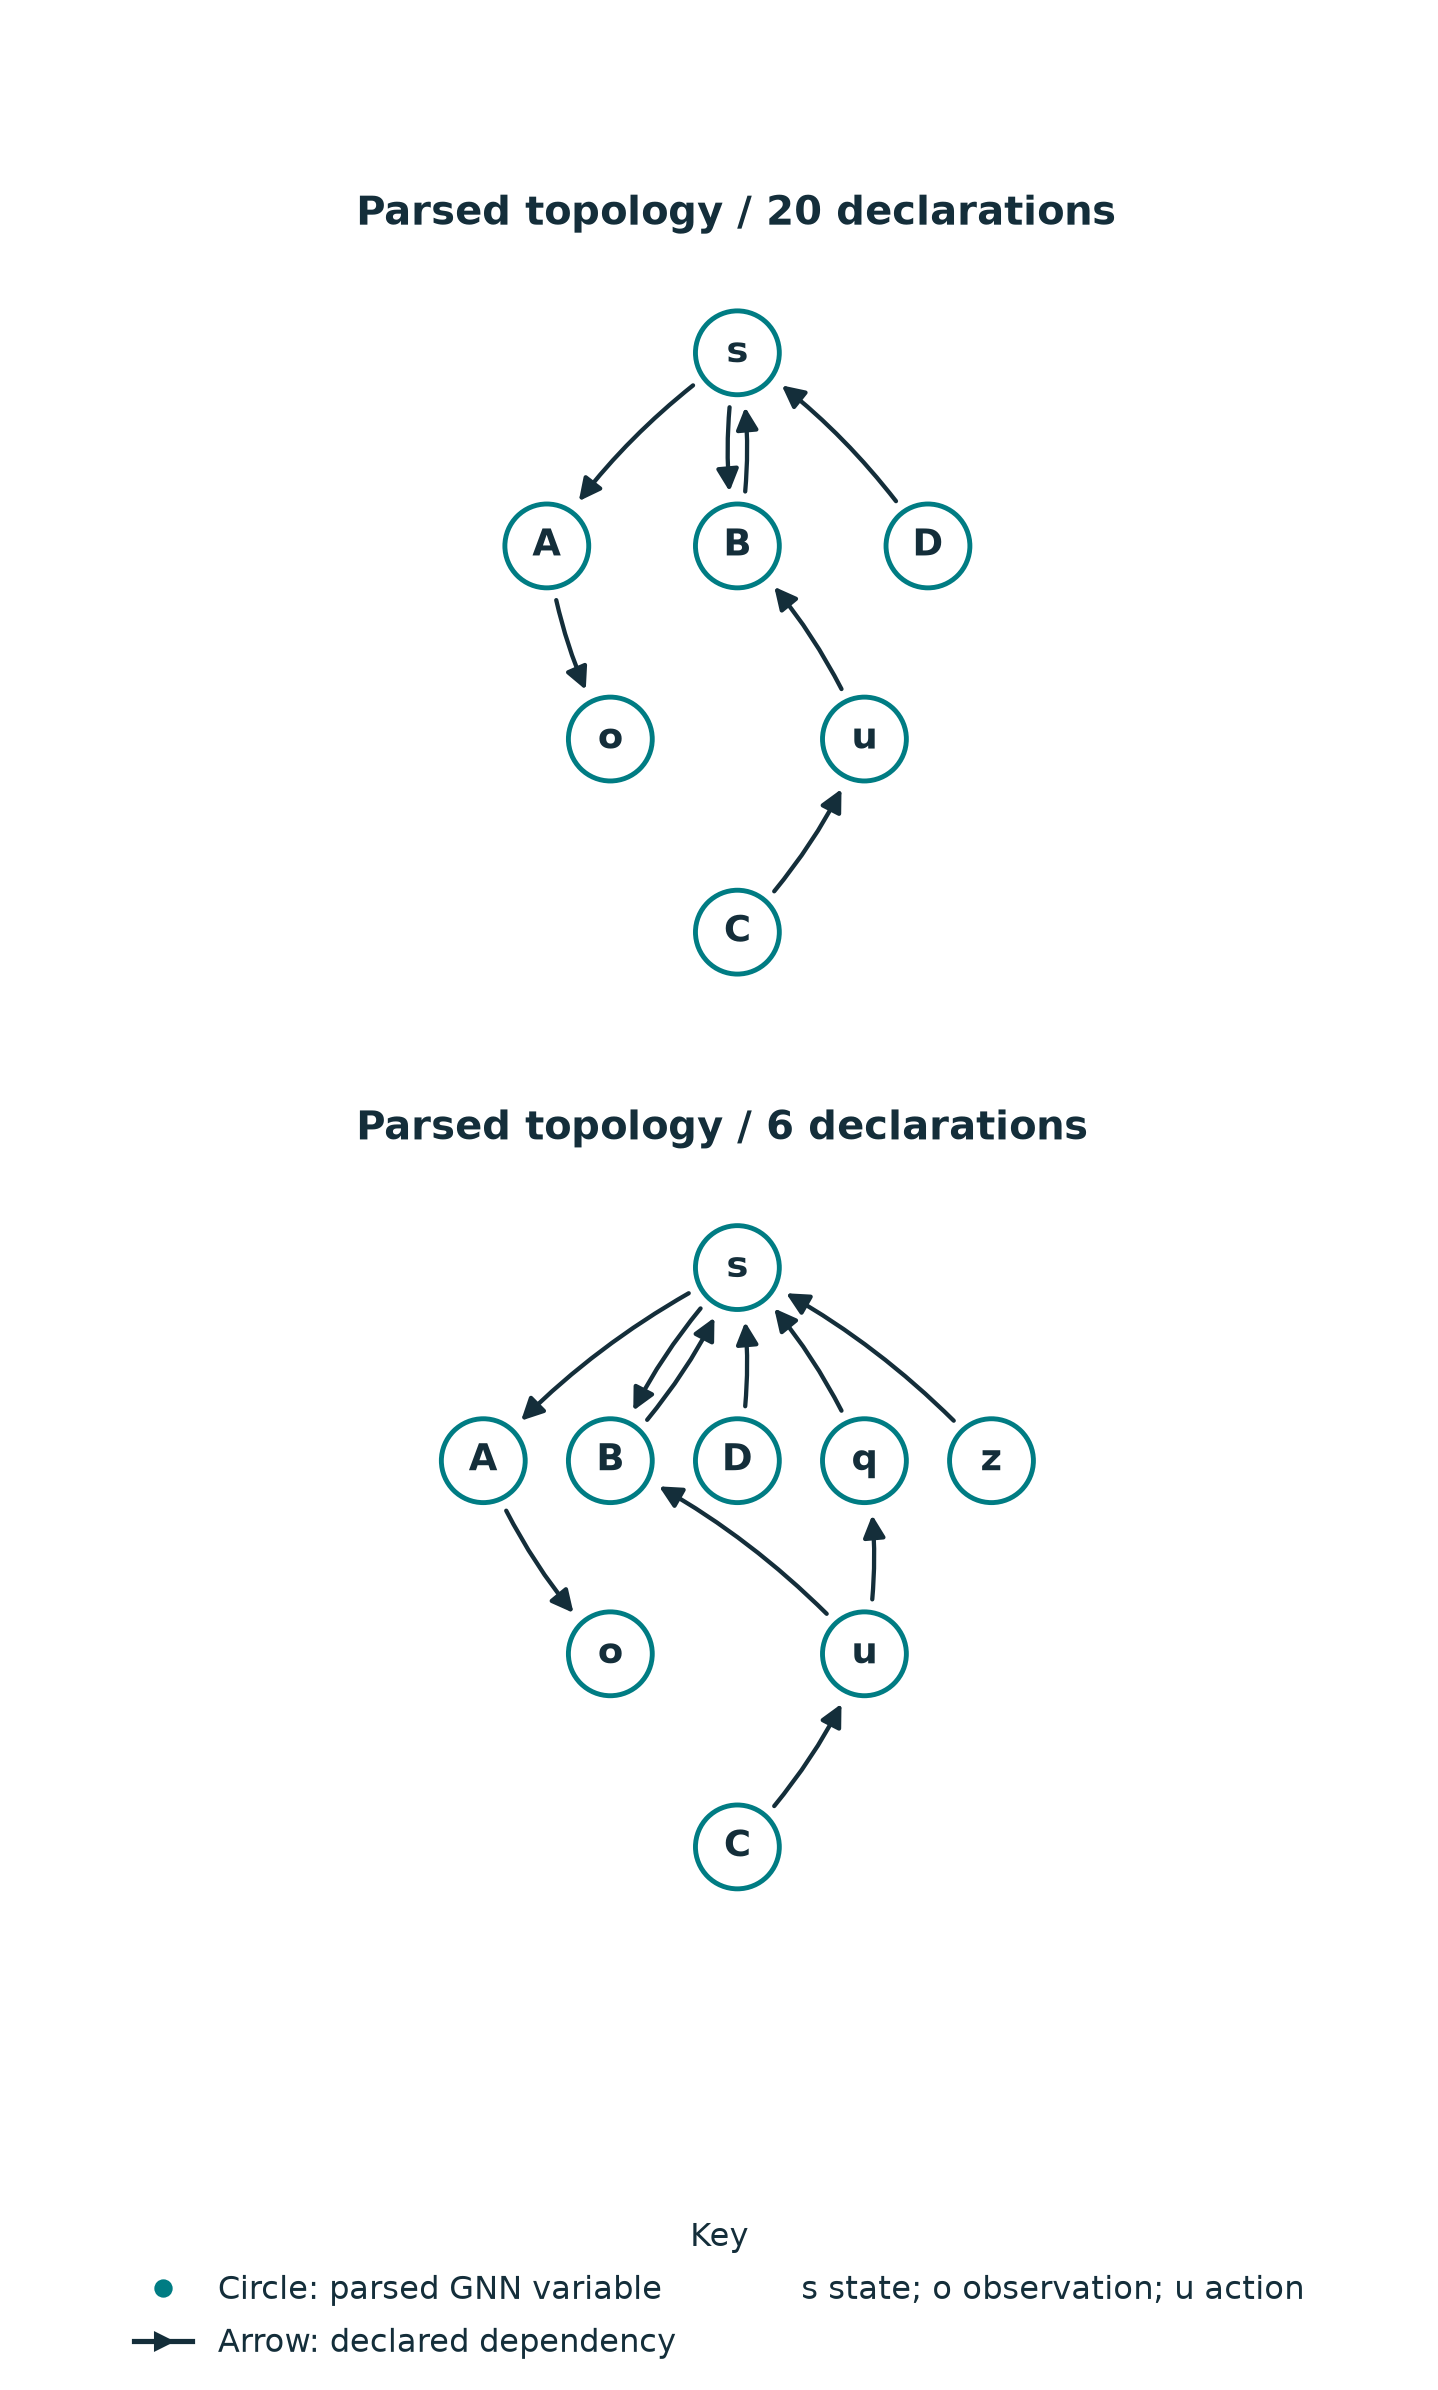

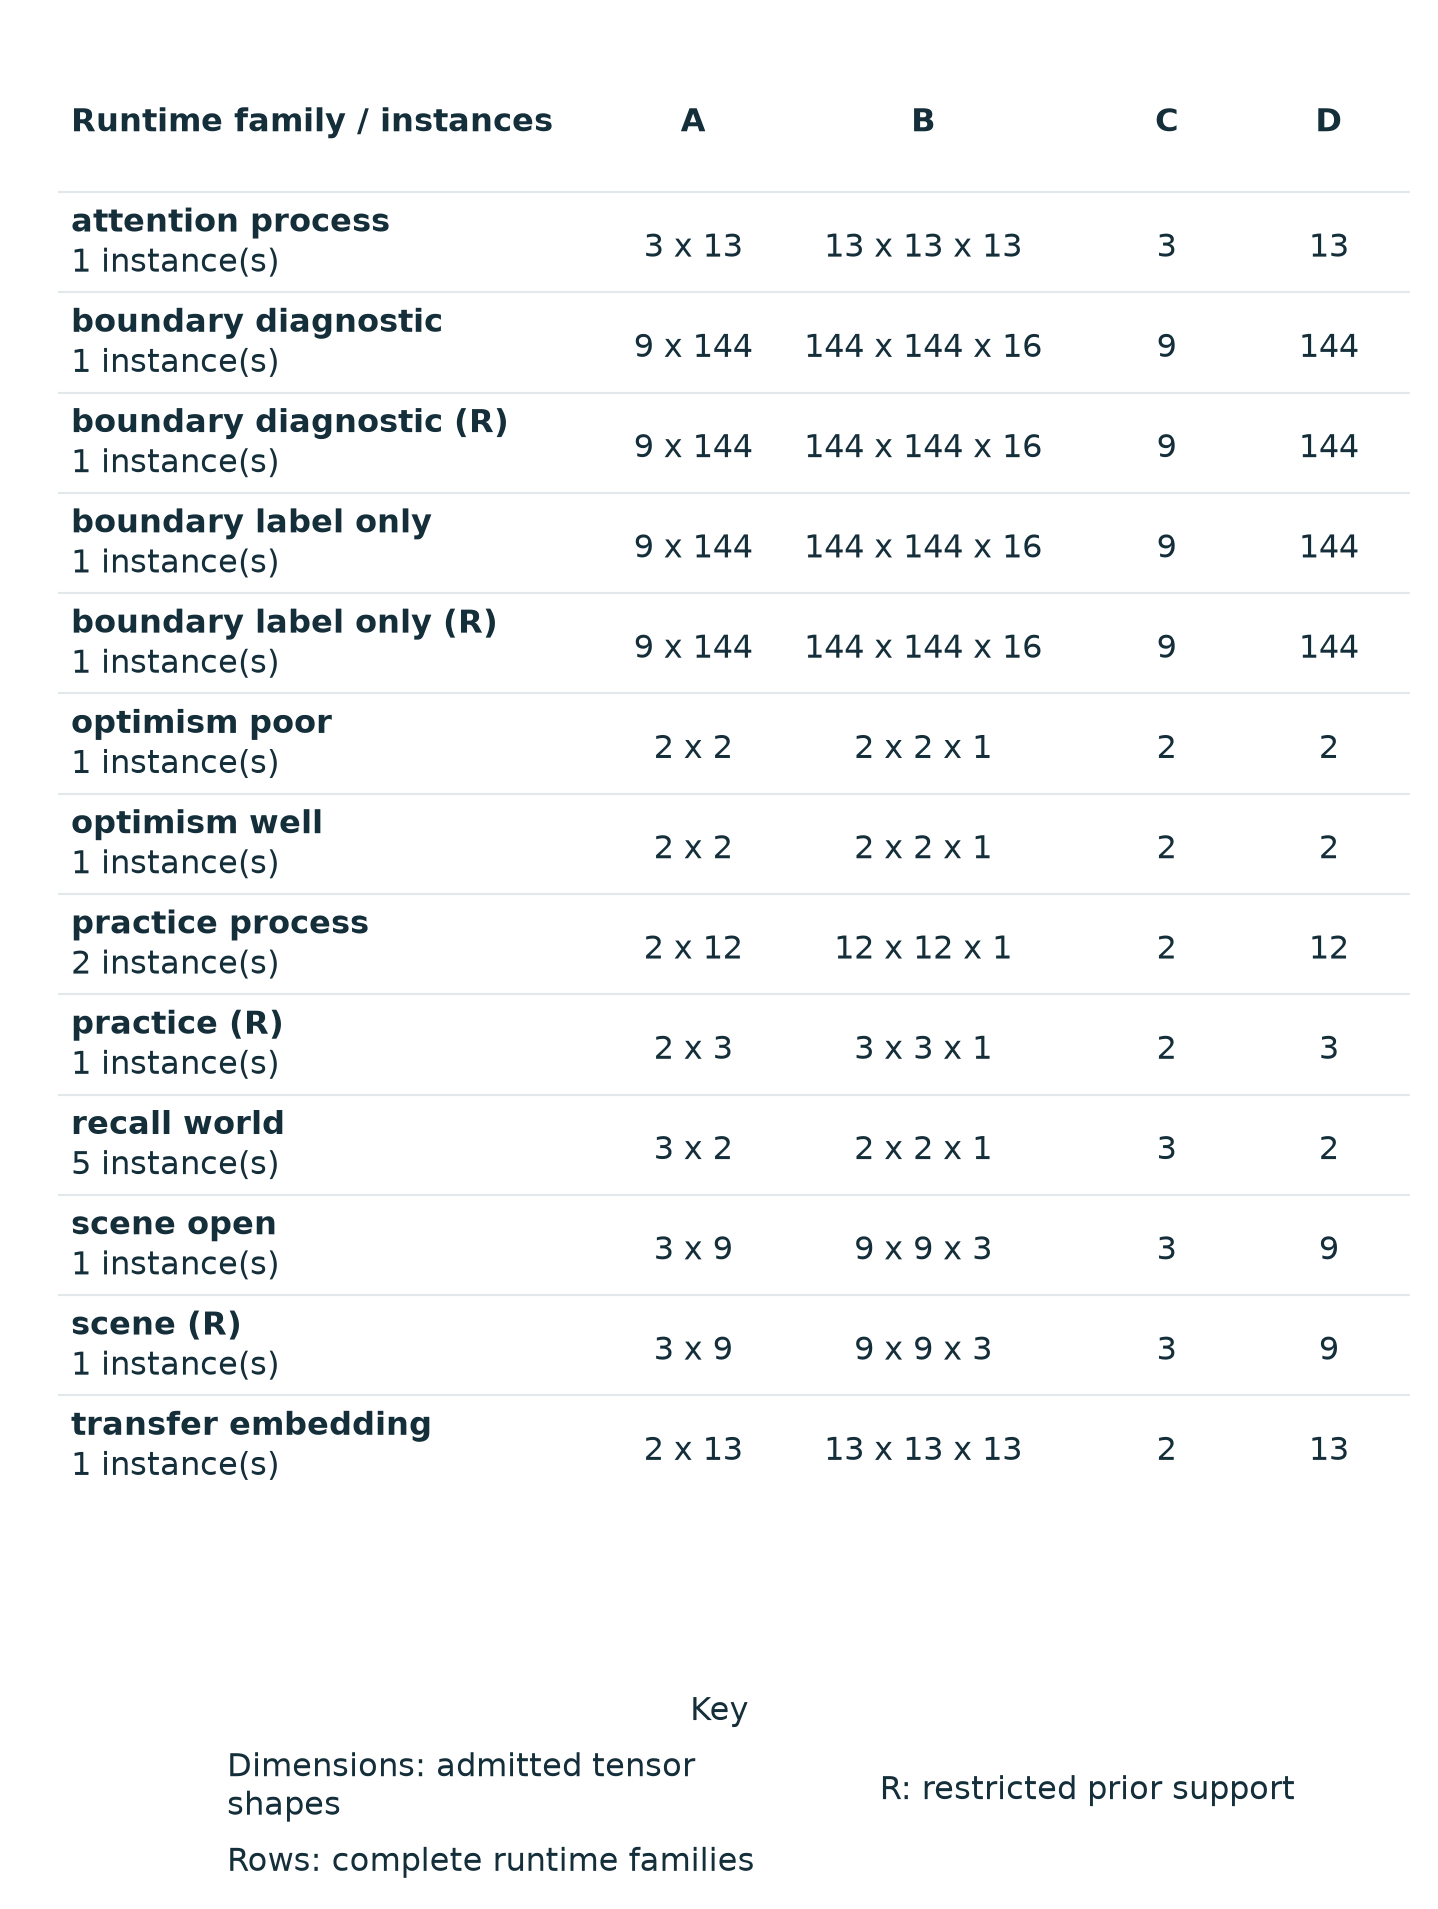

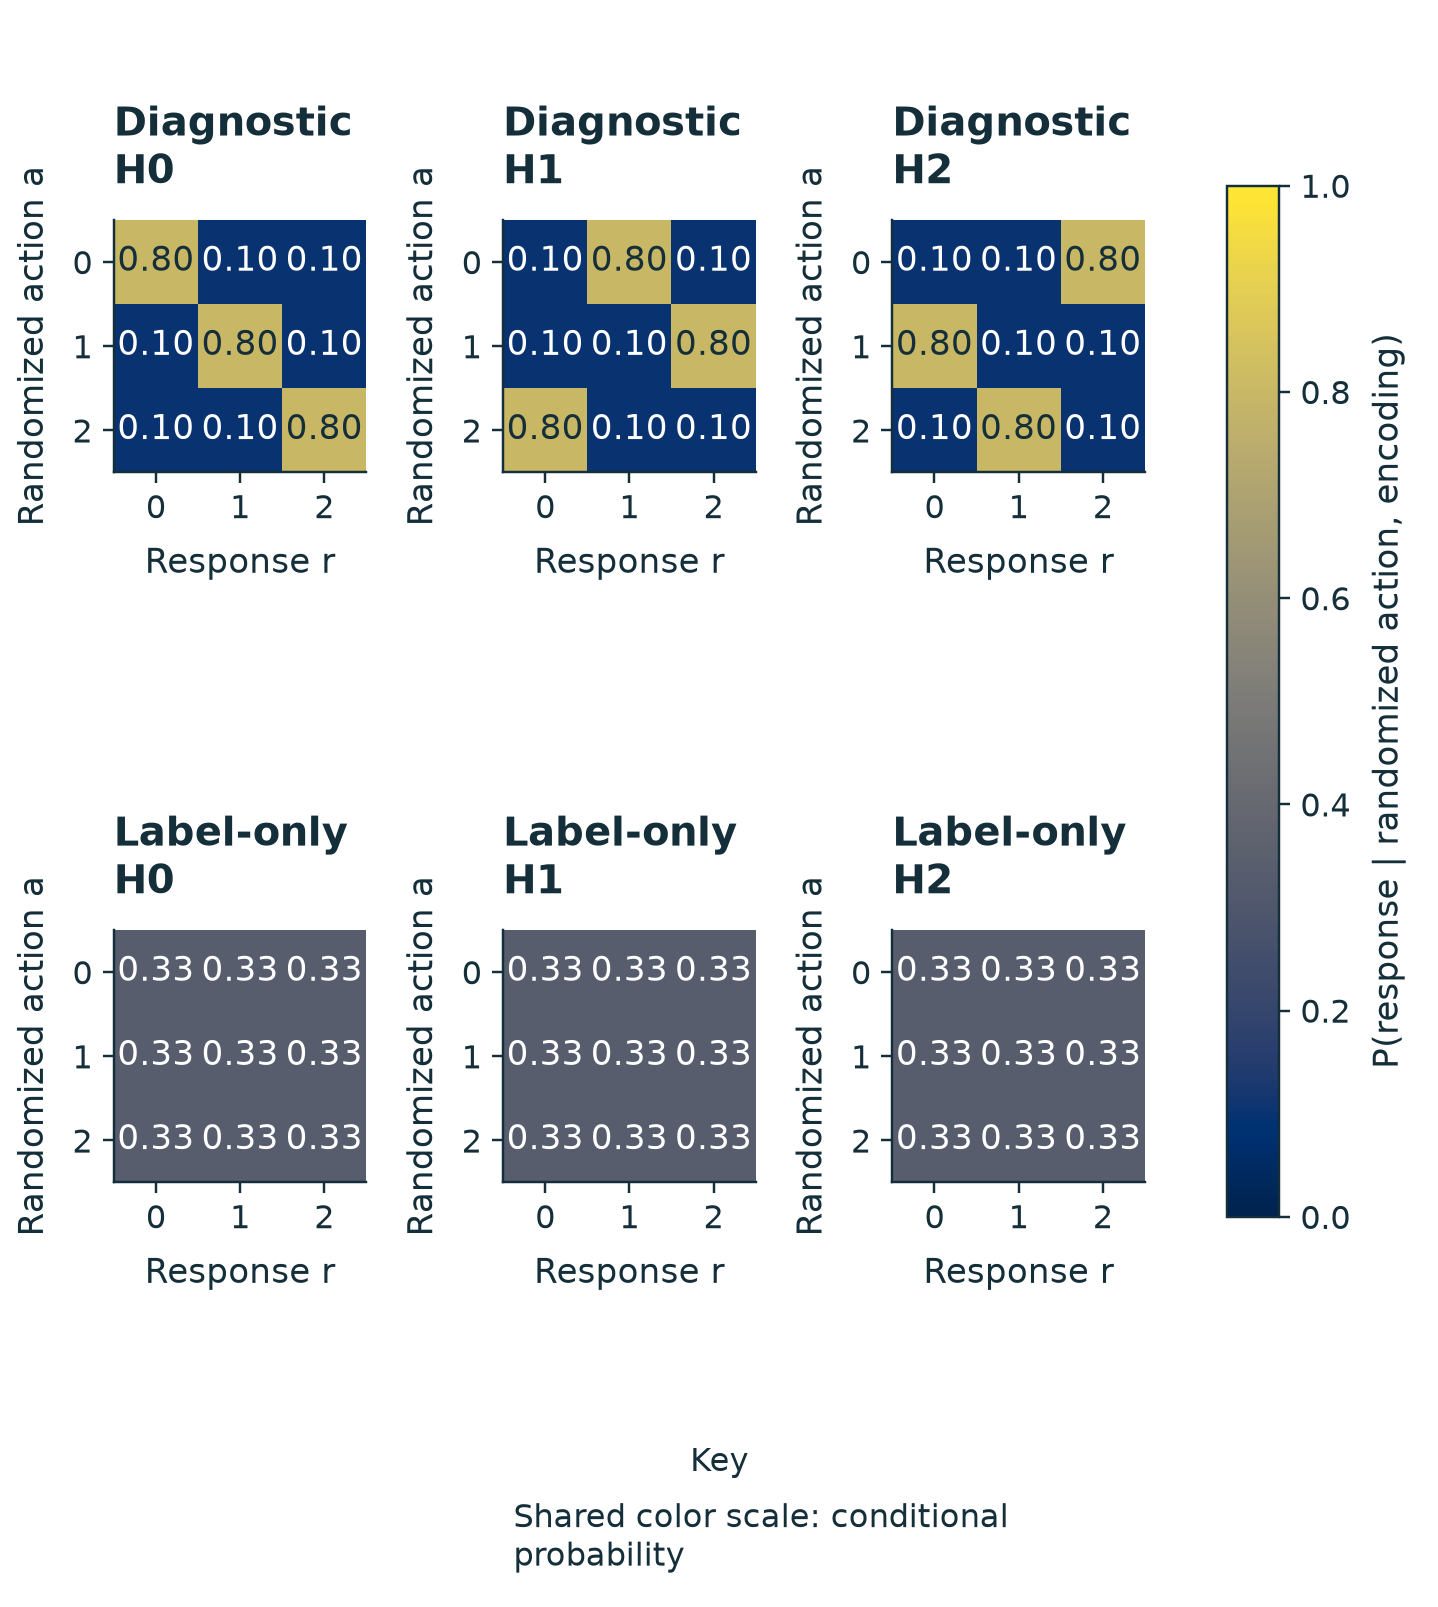

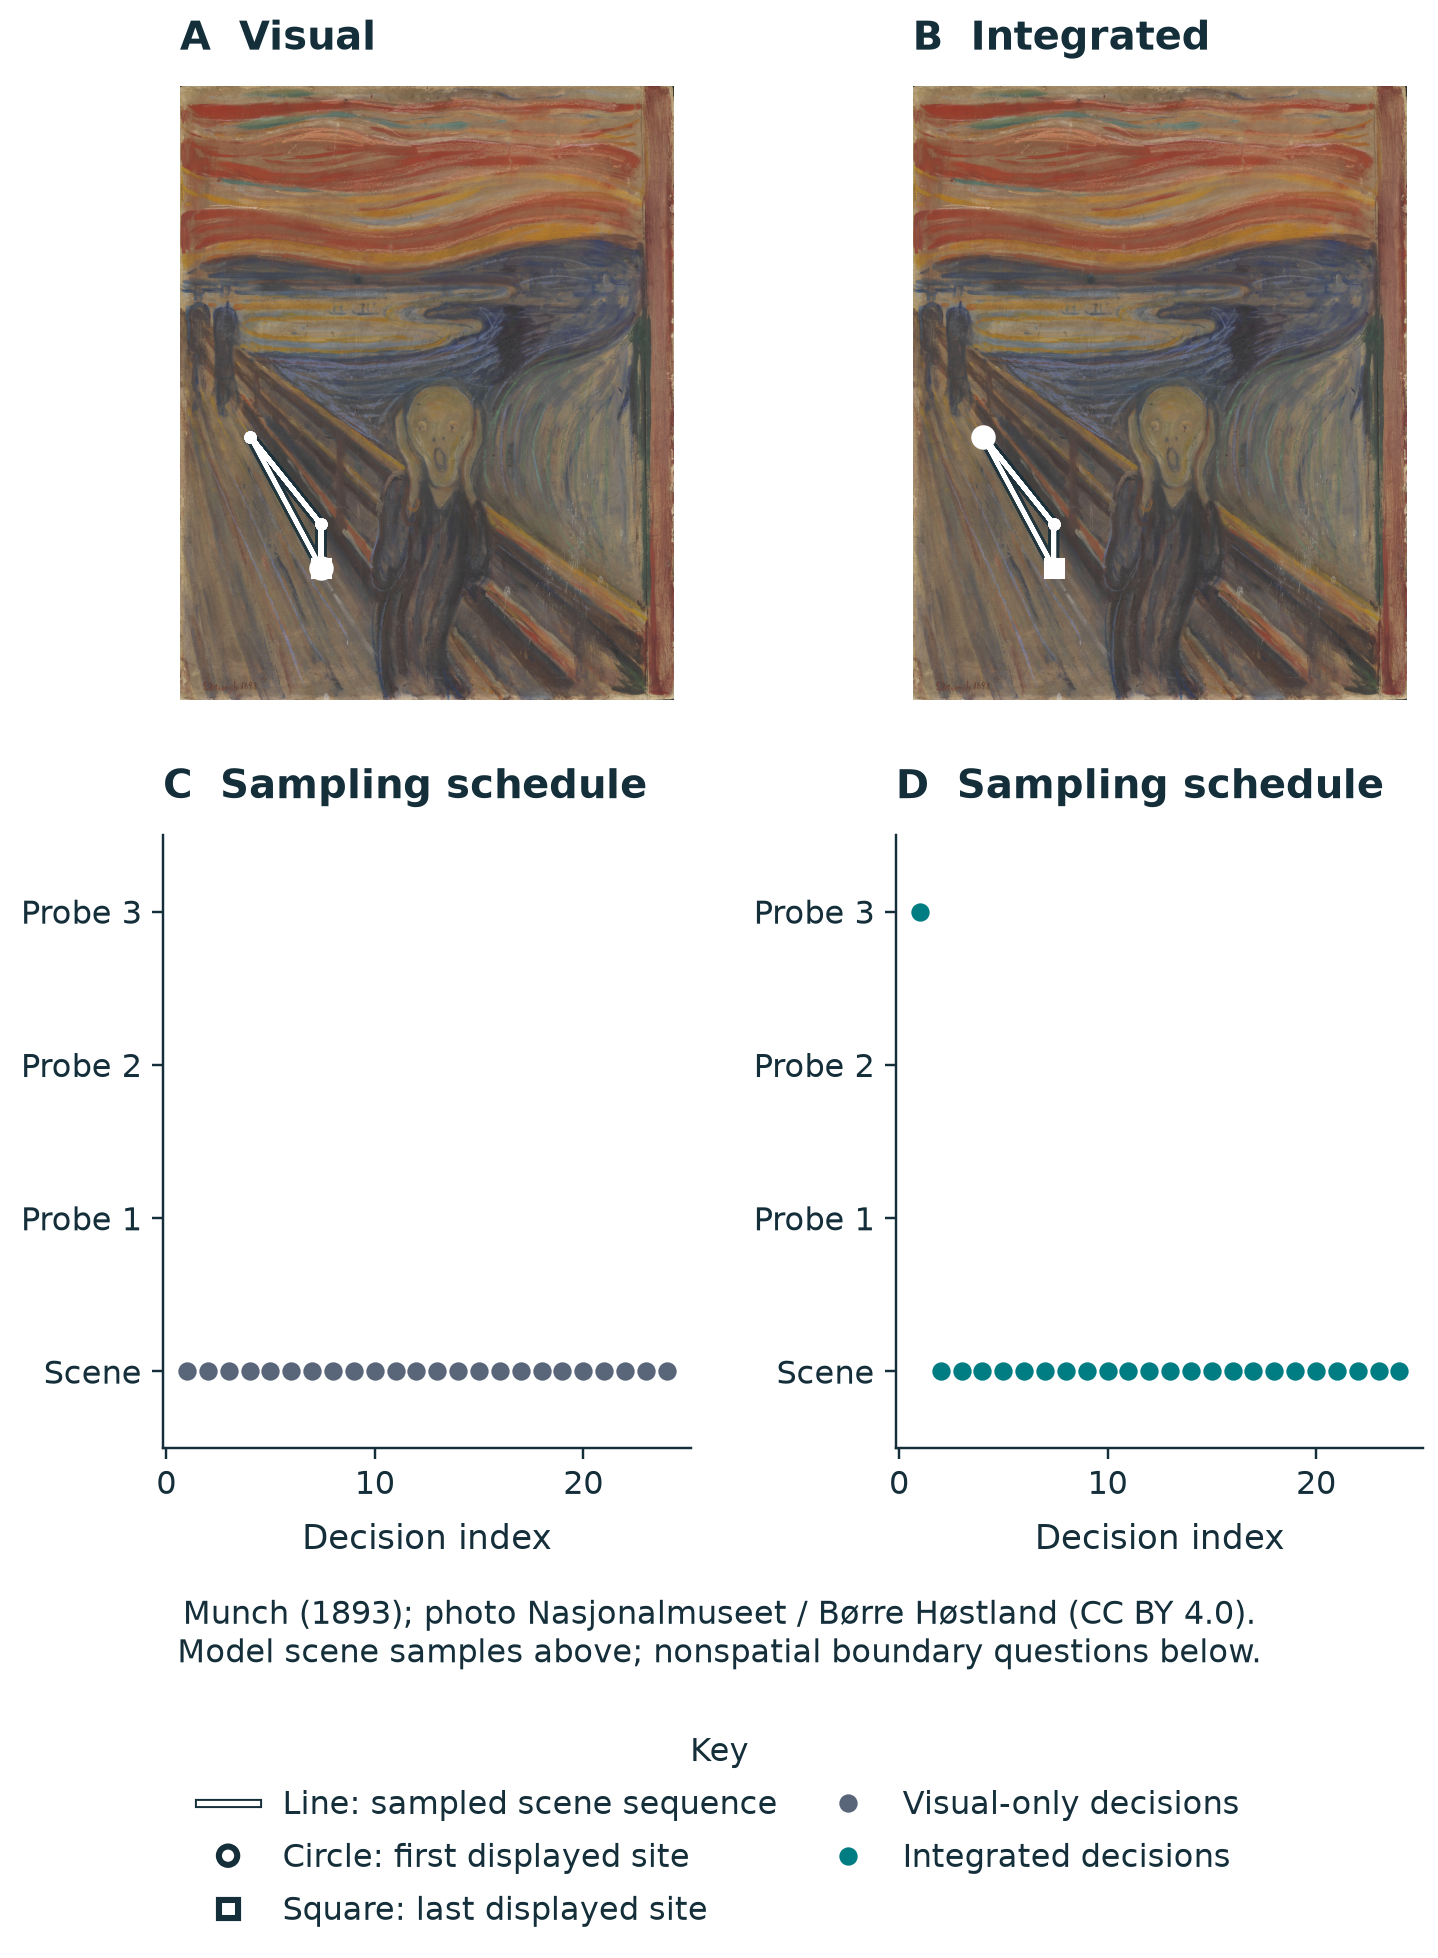

In [9]:
for name in ("gnn_model_graph", "gnn_model_tensors", "boundary_information", "boundary_gaze_paths"):
    display(Image(filename=str(OUTPUT / "figures" / (name + ".png"))))

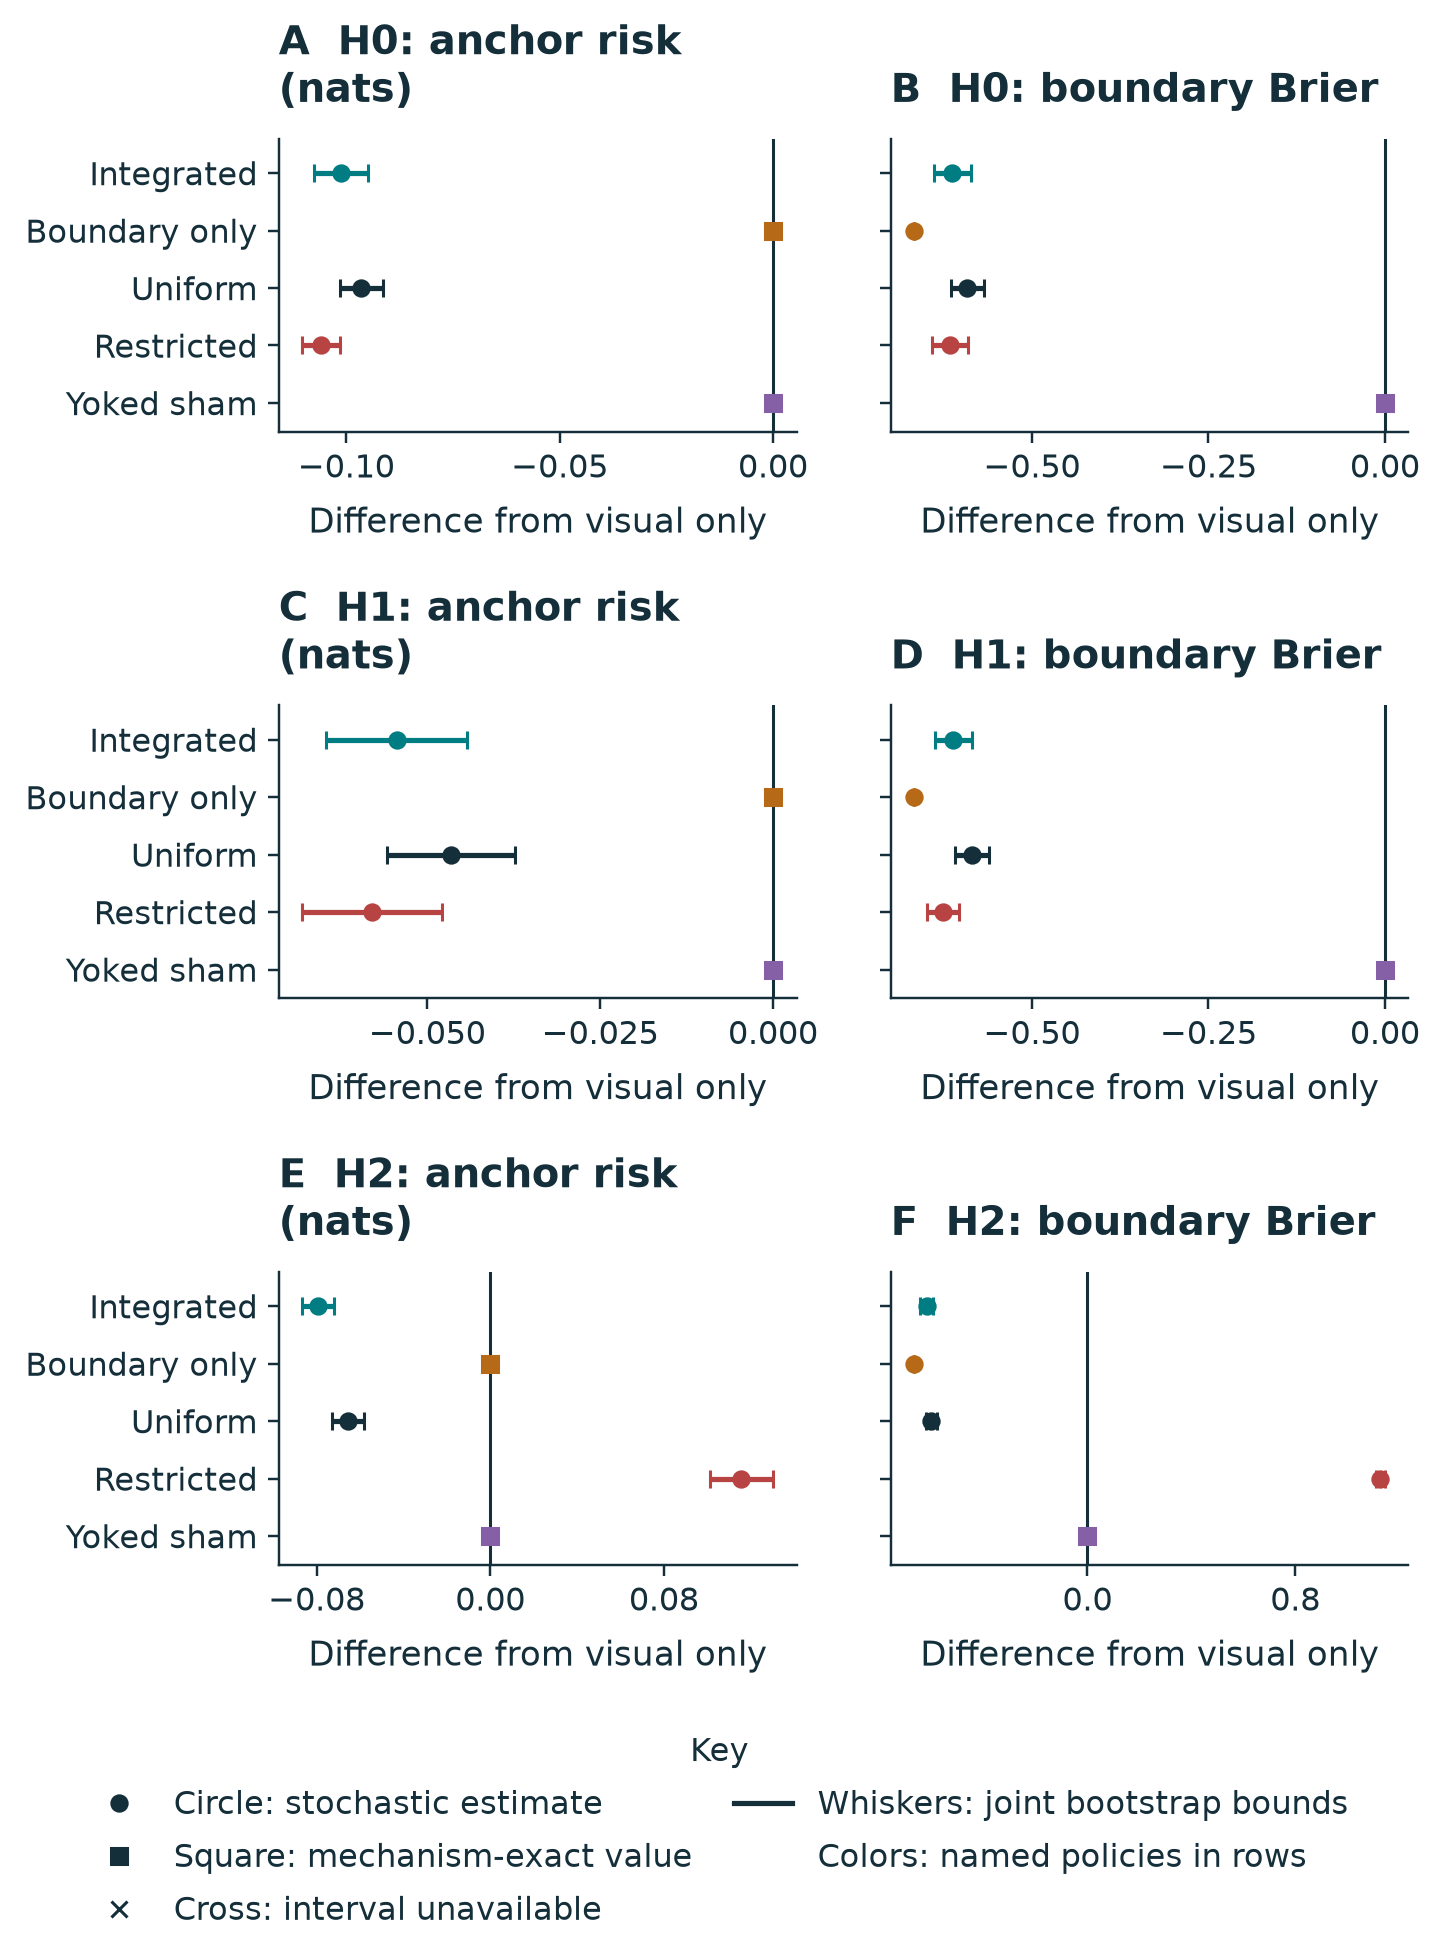

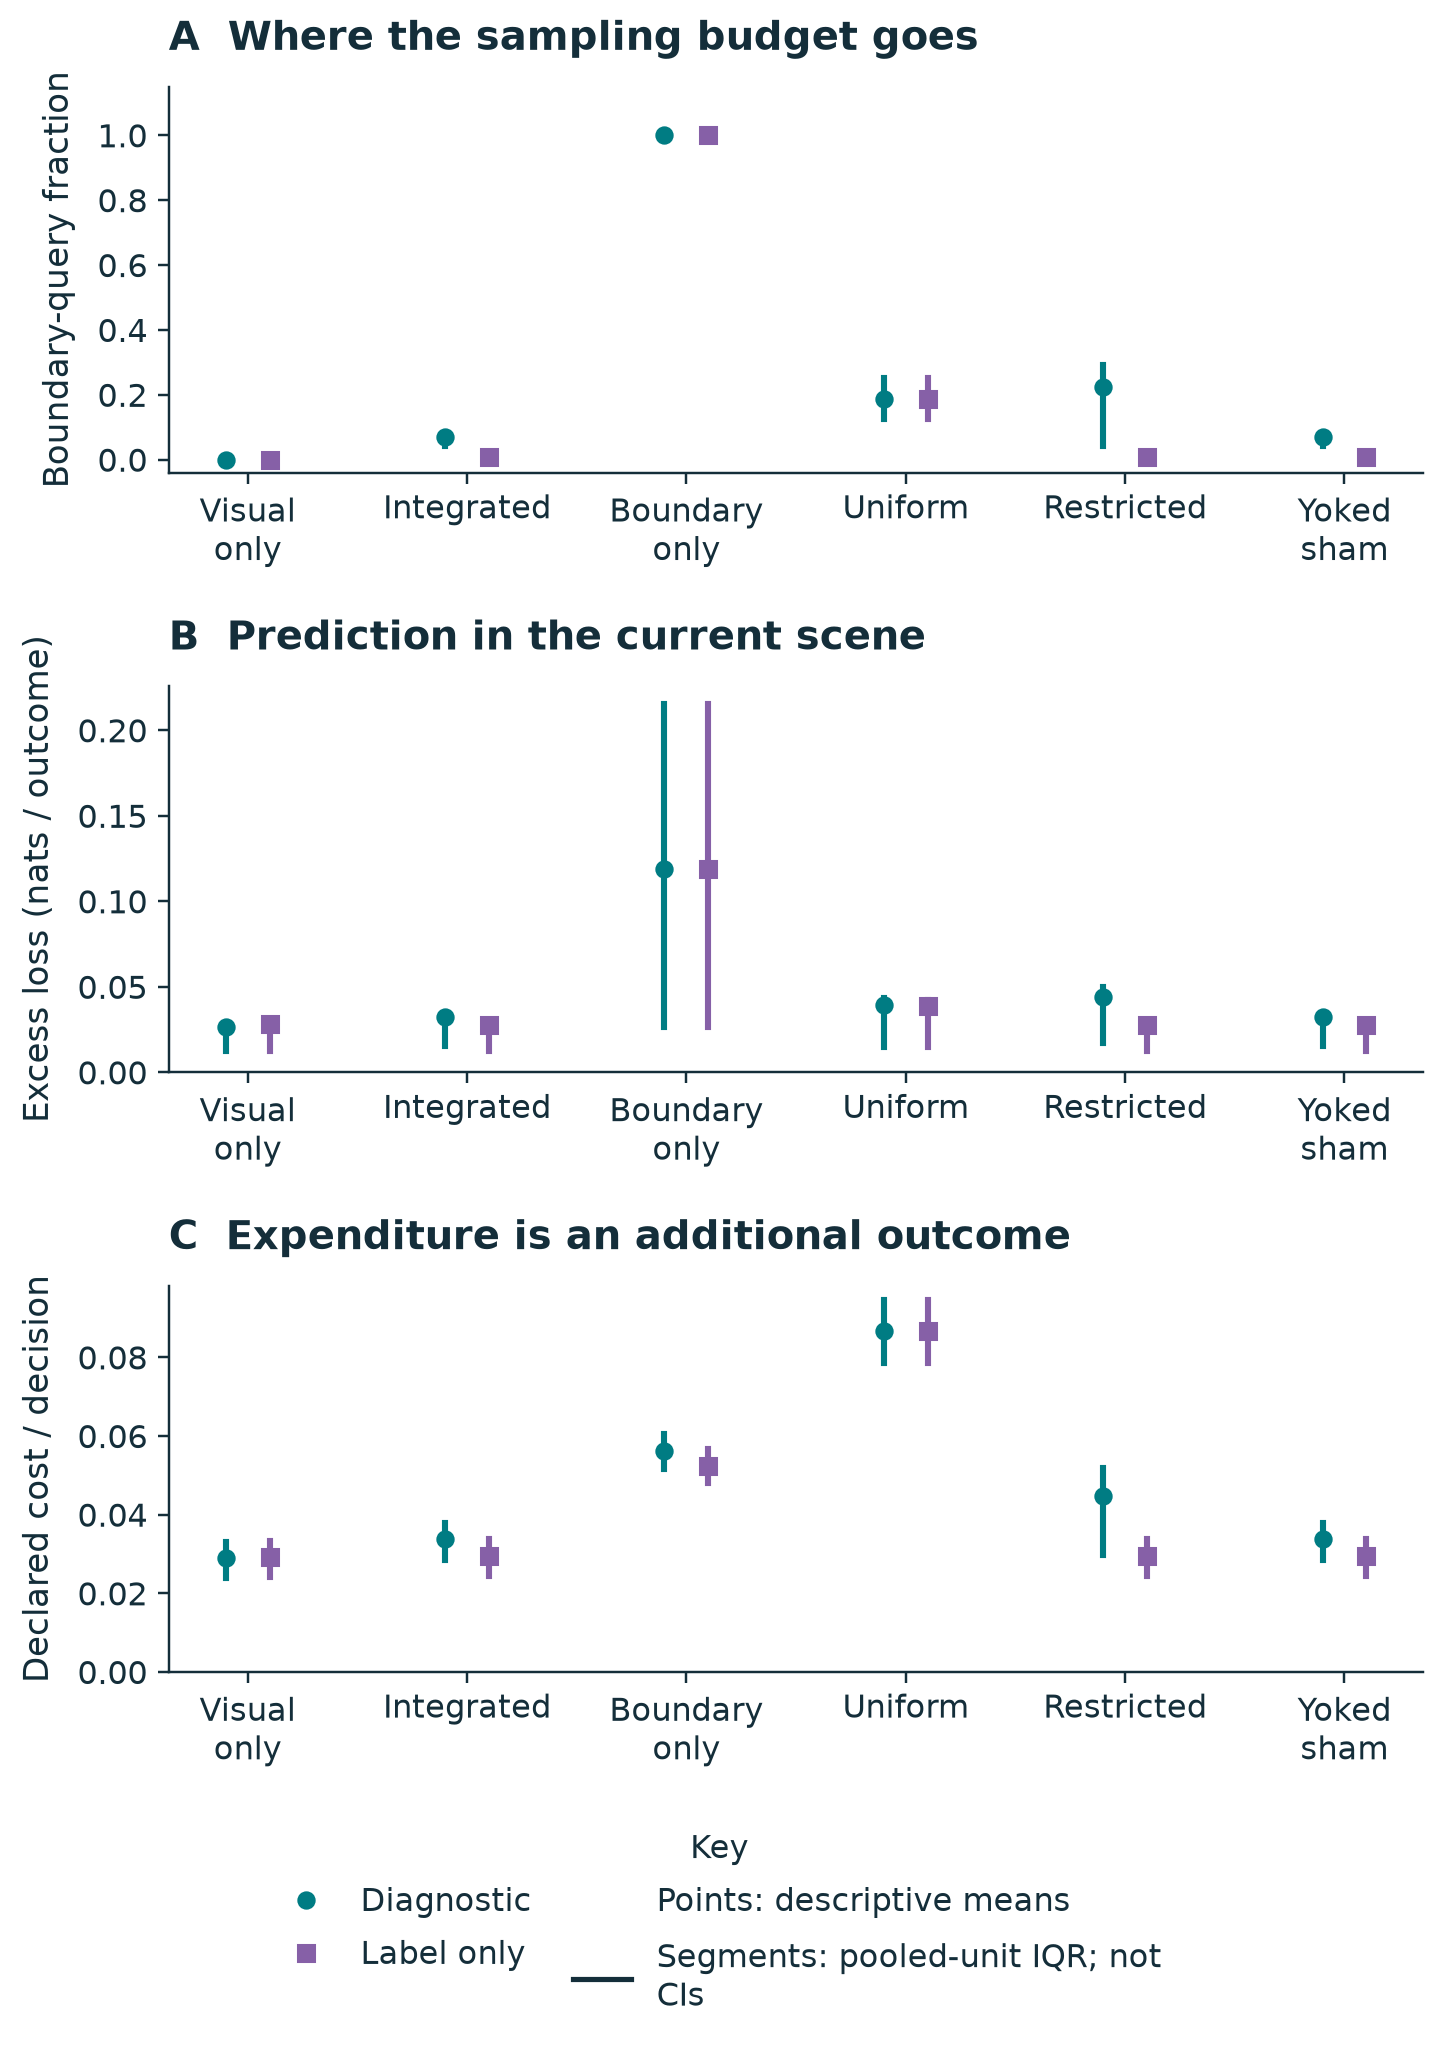

In [10]:
for name in ("boundary_gaze_outcomes", "boundary_gaze_allocation"):
    display(Image(filename=str(OUTPUT / "figures" / (name + ".png"))))

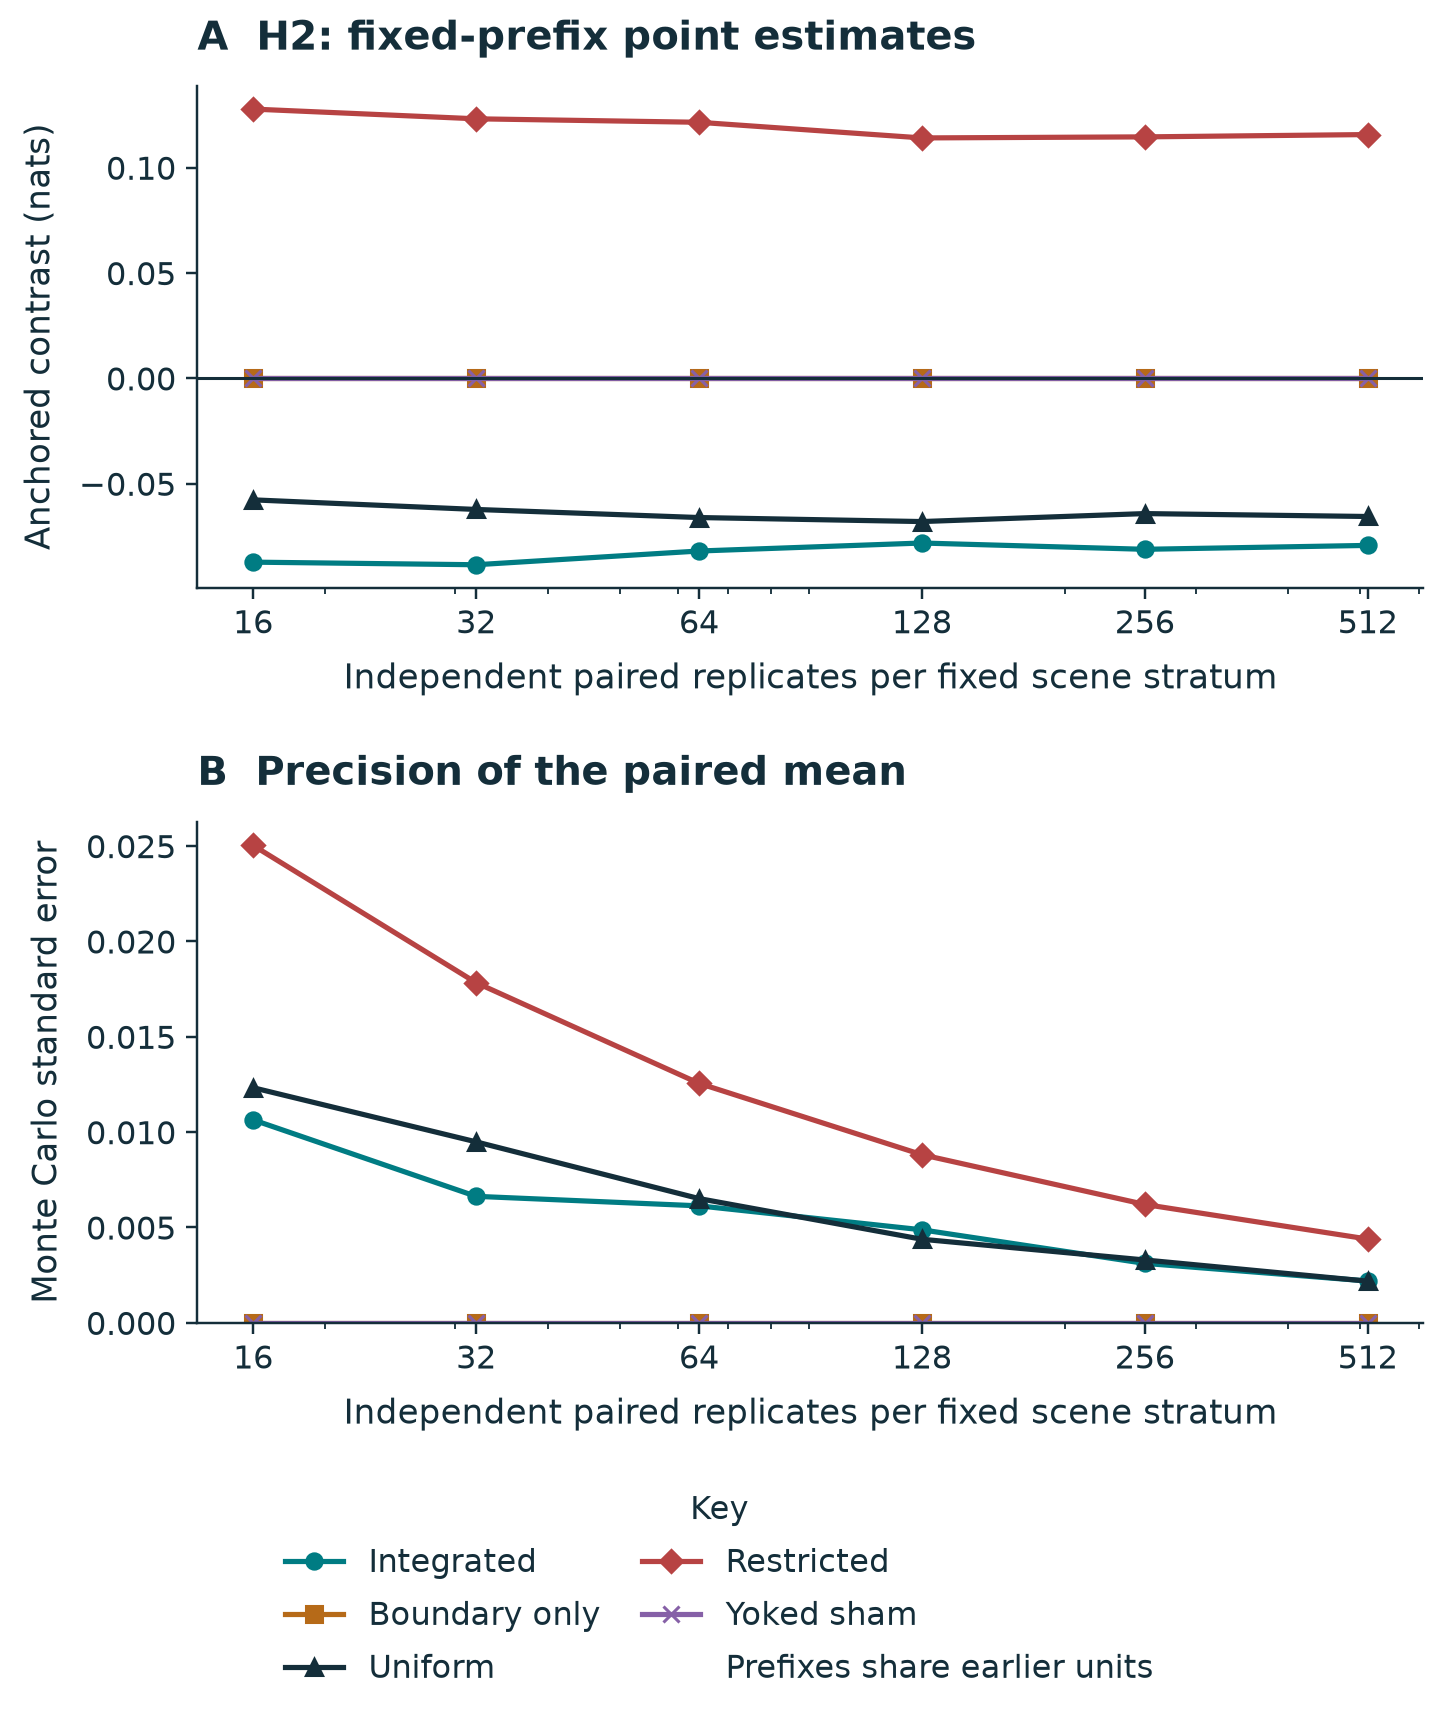

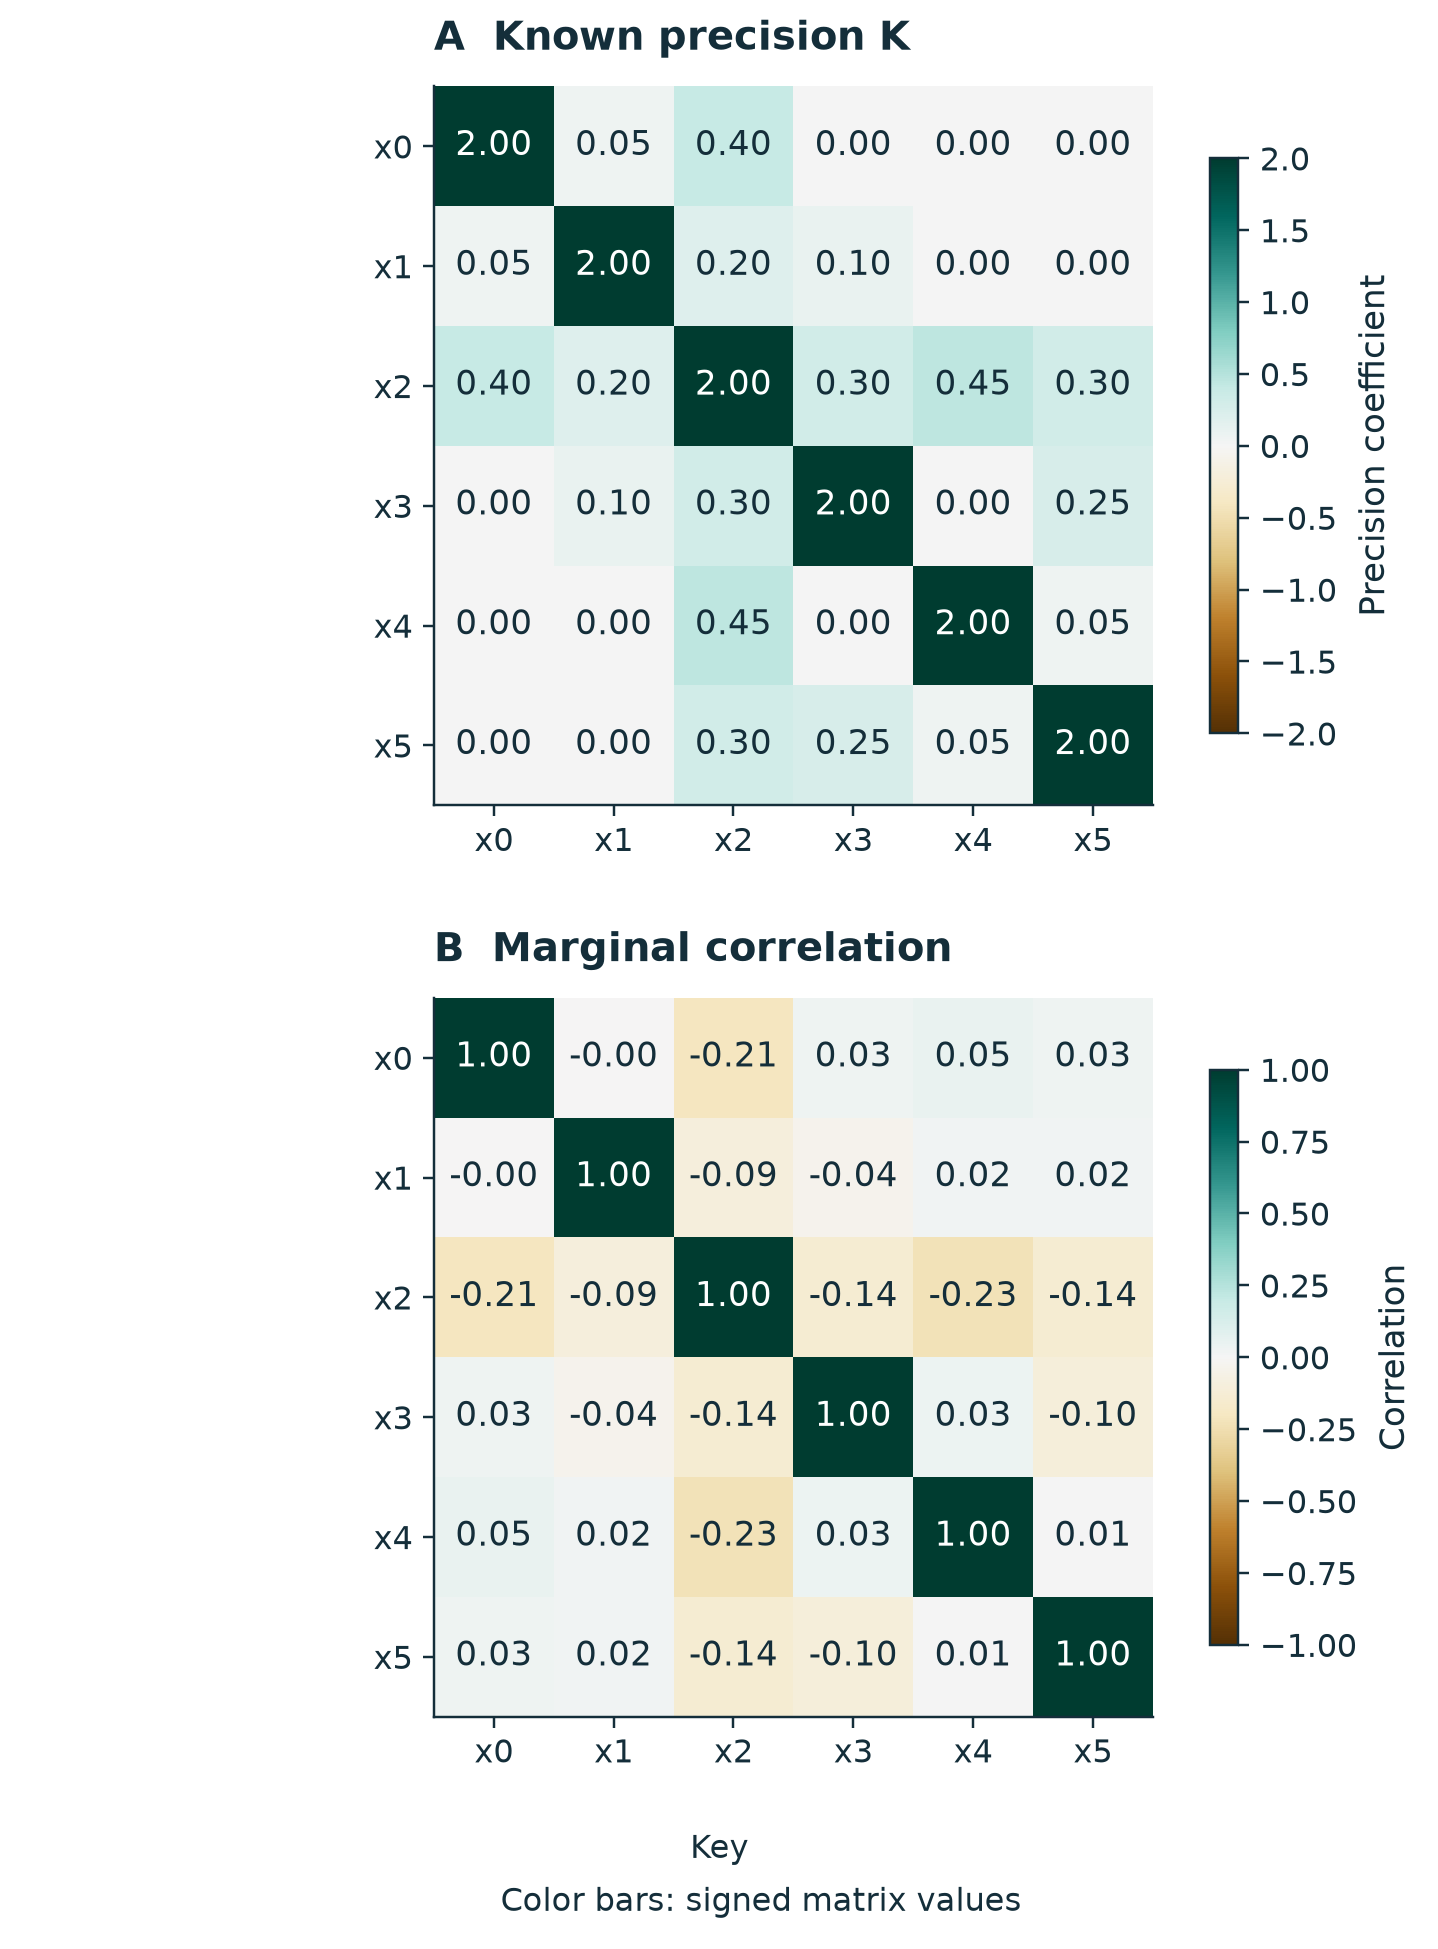

In [11]:
for name in ("boundary_gaze_convergence", "boundary_structure"):
    display(Image(filename=str(OUTPUT / "figures" / (name + ".png"))))

## Interpretation

Scene-only and boundary-only inference can each be insufficient for the anchored reference scene. Joint information can help when the declared contingency laws differ. Label-only identities, excluded hypotheses and current-scene opportunity costs remain counterexamples to a universal benefit claim. The complete separate joint family uses the original standard errors; exact constants require mathematical proofs, while unsupported sample constants stay unavailable. Coverage stress tests remain relevant to nearly deterministic endpoints.

A preference for practicing realization of emptiness is a conceptual orientation toward examining and revising useful constructions. This model supplies one finite inquiry mechanism. It does not measure that orientation, gratitude, human meta-awareness or realization.